#Linear Regression with Gradient Descent

In [74]:
import numpy as np
import matplotlib.pyplot as plt

## 1.Dataset Preparation


### Loading the Dataset

In [75]:
from sklearn.datasets import load_diabetes
diabetes_data = load_diabetes()

In [76]:
diabetes_data

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]]),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142., 155., 225.,  59

In [77]:
X_all = diabetes_data.data
y_all = diabetes_data.target
feature_names = diabetes_data.feature_names

print(f"X_all.shape: {X_all.shape}")
print(f"y_all.shape: {y_all.shape}")
print(f"feature_names: {feature_names}")

X_all.shape: (442, 10)
y_all.shape: (442,)
feature_names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [78]:
X_all[:2], y_all[:2]

(array([[ 0.03807591,  0.05068012,  0.06169621,  0.02187239, -0.0442235 ,
         -0.03482076, -0.04340085, -0.00259226,  0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, -0.02632753, -0.00844872,
         -0.01916334,  0.07441156, -0.03949338, -0.06833155, -0.09220405]]),
 array([151.,  75.]))

## 2. Shuffle and split into train / dev / test (70 % / 15 % / 15 %)



In [79]:
rng = np.random.default_rng(1)

n_samples = X_all.shape[0]
indices = np.arange(n_samples)
rng.shuffle(indices)

X_all_shuffled = X_all[indices]
y_all_shuffled = y_all[indices]


n_train = int(0.7 * n_samples)
n_dev = int(0.15 * n_samples)
n_test = n_samples - n_train - n_dev

X_train = X_all_shuffled[:n_train]
y_train = y_all_shuffled[:n_train]
X_dev = X_all_shuffled[n_train:n_train+n_dev]
y_dev = y_all_shuffled[n_train:n_train+n_dev]
X_test = X_all_shuffled[n_train+n_dev:]
y_test = y_all_shuffled[n_train+n_dev:]

## Check all shuffled data kept appropiate labels

In [80]:
# Sanity check: find each shuffled row in the original data by its feature values
# (independent of `indices`) and confirm its label moved with it.
for i in range(n_samples):
    orig_row = np.flatnonzero((X_all == X_all_shuffled[i]).all(axis=1))
    assert len(orig_row) == 1, f"Shuffled row {i} not found uniquely in X_all"
    assert y_all[orig_row[0]] == y_all_shuffled[i], f"Label mismatch at shuffled row {i}"

print("All features and labels still matched after shuffling")
for i in range(3):
    print(f"shuffled[{i}] <- original[{indices[i]}]: y_shuffled={y_all_shuffled[i]:.0f}, y_original={y_all[indices[i]]:.0f}")

All features and labels still matched after shuffling
shuffled[0] <- original[15]: y_shuffled=171, y_original=171
shuffled[1] <- original[29]: y_shuffled=283, y_original=283
shuffled[2] <- original[414]: y_shuffled=131, y_original=131


## 3. Two-variable linear regression with gradient descent

Model: $\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2$

In [81]:
# The diabetes features are pre-scaled to tiny values (about ±0.1), which makes gradient
# descent very slow. Standardize them using train-set statistics only, so no dev/test
# information leaks into training.
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
X_train_std = (X_train - mu) / sigma
X_dev_std = (X_dev - mu) / sigma
X_test_std = (X_test - mu) / sigma

## Building Model ##
# Linear Regression Model: X has two columns, one per feature
def linear_regression(theta, X):
    pred = theta[0] + theta[1]*X[:, 0] + theta[2]*X[:, 1]
    return pred

# Cost Function
def compute_cost(Y_pred, Y_true):
    m = len(Y_true)
    J = 1/(2*m) * np.sum((Y_pred - Y_true)**2)
    return J

# Gradient Descent
def update_theta(theta, X, Y_true, Y_pred, learning_rate):
    m = len(Y_true)
    # Y_pred is pre-computed, so all thetas are updated simultaneously
    error = Y_pred - Y_true
    theta[0] = theta[0] - (learning_rate * (1/m) * np.sum(error))
    theta[1] = theta[1] - (learning_rate * (1/m) * np.sum(error * X[:, 0]))
    theta[2] = theta[2] - (learning_rate * (1/m) * np.sum(error * X[:, 1]))
    return theta

# Mean squared error, the metric we report (compute_cost is MSE / 2)
def mse(Y_pred, Y_true):
    return np.mean((Y_pred - Y_true)**2)

## Train the model ##
def train(X, Y, lr=0.1, n_iters=150):
    theta = [0.0, 0.0, 0.0]
    costs = []
    for i in range(n_iters):
        pred = linear_regression(theta, X)
        costs.append(compute_cost(pred, Y))
        theta = update_theta(theta, X, Y, pred, lr)
    return theta, costs

## 4. Feature selection: train all 45 feature pairs and keep the best one on the dev set

In [82]:
results = []
for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        theta, costs = train(X_train_std[:, [i, j]], y_train)
        dev_mse = mse(linear_regression(theta, X_dev_std[:, [i, j]]), y_dev)
        results.append((dev_mse, i, j, theta, costs))

results.sort(key=lambda r: r[0])
print(f"Trained {len(results)} models. Top 5 by dev MSE:")
for dev_mse, i, j, _, _ in results[:5]:
    print(f"  {feature_names[i]:>4} + {feature_names[j]:<4}  dev MSE = {dev_mse:.2f}")

# Save best available parameters
best_dev_mse, best_i, best_j, best_theta, best_costs = results[0]
best_features = [best_i, best_j]
print(f"\nBest pair: {feature_names[best_i]} + {feature_names[best_j]}")

Trained 45 models. Top 5 by dev MSE:
   bmi + s5    dev MSE = 2915.88
    bp + s5    dev MSE = 3124.16
    s3 + s5    dev MSE = 3283.86
    s1 + s5    dev MSE = 3310.01
   bmi + s3    dev MSE = 3316.85

Best pair: bmi + s5


## 5. Test the model

Features: bmi, s5
theta: [154.8123, 33.5738, 29.5272]
Train MSE: 3245.04
Dev MSE:   2915.88
Test MSE:  3328.16



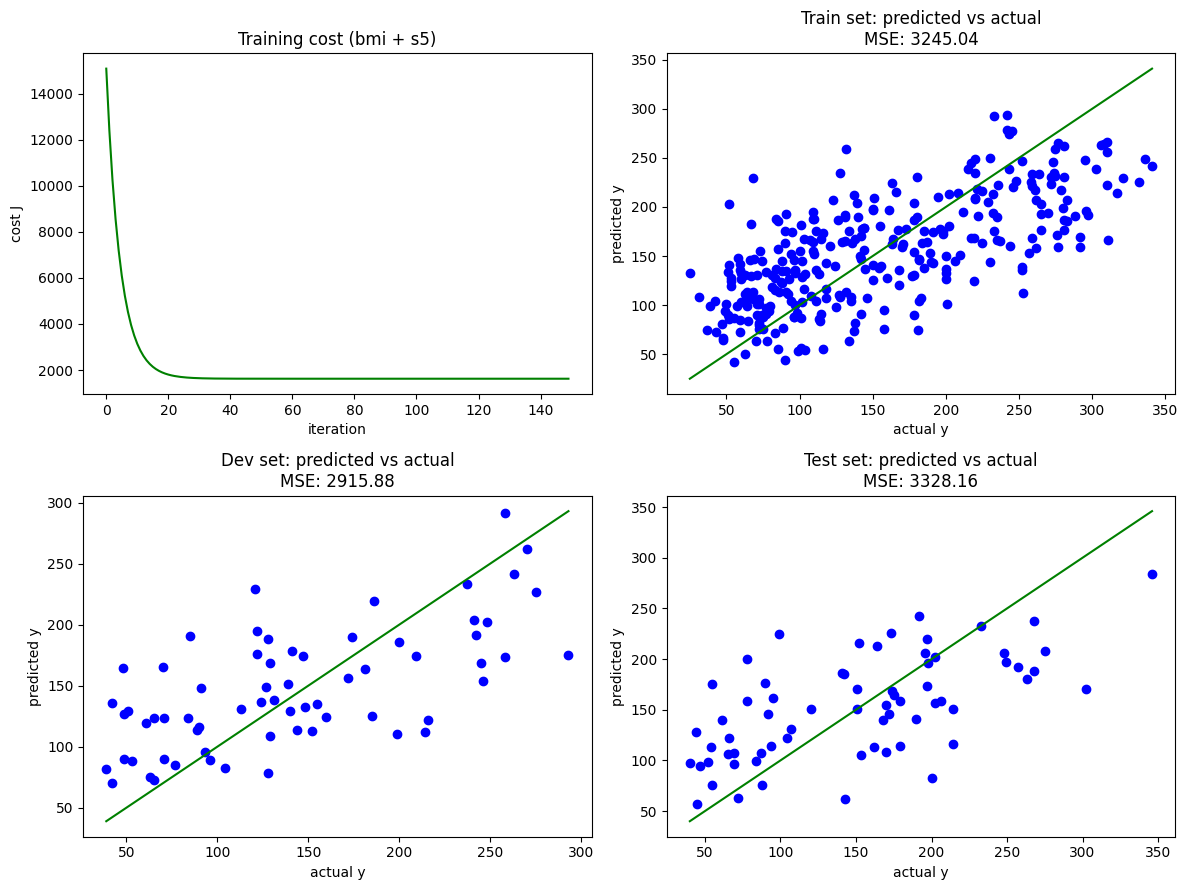

In [85]:
train_pred = linear_regression(best_theta, X_train_std[:, best_features])
train_mse = mse(train_pred, y_train)
dev_pred = linear_regression(best_theta, X_dev_std[:, best_features])
test_pred = linear_regression(best_theta, X_test_std[:, best_features])
test_mse = mse(test_pred, y_test)

print(f"Features: {feature_names[best_i]}, {feature_names[best_j]}")
print(f"theta: [{best_theta[0]:.4f}, {best_theta[1]:.4f}, {best_theta[2]:.4f}]")
print(f"Train MSE: {train_mse:.2f}")
print(f"Dev MSE:   {best_dev_mse:.2f}")
print(f"Test MSE:  {test_mse:.2f}")
print('')
plt.figure(figsize=(12, 9))

plt.subplot(2, 2, 1)
plt.plot(best_costs, 'g')
plt.xlabel('iteration')
plt.ylabel('cost J')
plt.title('Training cost (%s + %s)' % (feature_names[best_i], feature_names[best_j]))

plt.subplot(2, 2, 2)
plt.scatter(y_train, train_pred, color='b')
lims = [y_train.min(), y_train.max()]
plt.plot(lims, lims, 'g')
plt.xlabel('actual y')
plt.ylabel('predicted y')
plt.title('Train set: predicted vs actual\nMSE: %.2f' % train_mse)

plt.subplot(2, 2, 3)
plt.scatter(y_dev, dev_pred, color='b')
lims = [y_dev.min(), y_dev.max()]
plt.plot(lims, lims, 'g')
plt.xlabel('actual y')
plt.ylabel('predicted y')
plt.title('Dev set: predicted vs actual\nMSE: %.2f' % best_dev_mse)

plt.subplot(2, 2, 4)
plt.scatter(y_test, test_pred, color='b')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'g')
plt.xlabel('actual y')
plt.ylabel('predicted y')
plt.title('Test set: predicted vs actual\nMSE: %.2f' % test_mse)

plt.tight_layout()
plt.show()